<a href="https://colab.research.google.com/github/seo104/26-2-ESAA/blob/main/%ED%94%84%EB%A1%9C%EC%A0%9D%ED%8A%B82_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install imbalanced-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline

# 데이터 불러오기
train = pd.read_csv('/content/train.csv')
test = pd.read_csv('/content/test.csv')

# 데이터 크기
print('Train 데이터 크기:', train.shape)
print('Test 데이터 크기:', test.shape)

# 변수명과 자료형
display(pd.DataFrame({
    '변수명': train.columns,
    '자료형': train.dtypes.astype(str).values,
    '결측값 수': train.isnull().sum().values,
    '고유값 수': train.nunique().values
}))

X = train.drop(columns=['quality', 'index'])
X['type'] = X['type'].map({'red': 0, 'white': 1})
y = train['quality']

Train 데이터 크기: (5497, 14)
Test 데이터 크기: (1000, 13)


,변수명,자료형,결측값 수,고유값 수
0,index,int64,0,5497
1,quality,int64,0,7
2,fixed acidity,float64,0,106
3,volatile acidity,float64,0,179
4,citric acid,float64,0,89
5,residual sugar,float64,0,309
6,chlorides,float64,0,205
7,free sulfur dioxide,float64,0,127
8,total sulfur dioxide,float64,0,271
9,density,float64,0,970


In [2]:
#데이터 구성
data_info = pd.DataFrame({
    '구분': ['Train', 'Test'],
    '행 개수': [len(train), len(test)],
    '열 개수': [train.shape[1], test.shape[1]],
    '결측값 개수': [train.isnull().sum().sum(),
                  test.isnull().sum().sum()],
    '중복 행 개수': [train.duplicated().sum(),
                   test.duplicated().sum()]
})

display(data_info)

,구분,행 개수,열 개수,결측값 개수,중복 행 개수
0,Train,5497,14,0,0
1,Test,1000,13,0,0


##와인 종류별 특성 및 클래스 불균형 EDA

###분석 목표
레드 와인과 화이트 와인의 화학적 성분 및 품질 평가에 차이가 있는지 확인하고, 품질 등급의 클래스 불균형을 처리하는 것이 모델의 예측 정확도에 도움이 되는지 검증한다.

확인하려는 것은 크게 네 가지다.
1. 레드 와인과 화이트 와인의 성분 분포는 어떻게 다른가?
2. 와인 종류에 따라 평균 품질과 품질 등급 분포에 차이가 있는가?
3. 와인 종류에 따라 품질과 화학 성분 사이의 관계도 달라지는가?
4. 클래스 불균형을 처리했을 때 모델의 정확도가 향상되는가?

###1. 레드 와인과 화이트 와인의 데이터 구성
먼저 와인 종류별 데이터 개수와 비율을 확인한다.

In [3]:
type_count = train['type'].value_counts()

type_ratio = train['type'].value_counts(normalize=True) * 100

type_table = pd.DataFrame({
    '와인 종류': type_count.index,
    '데이터 개수': type_count.values,
    '비율(%)': type_ratio.values
})

display(type_table)

,와인 종류,데이터 개수,비율(%)
0,white,4159,75.659451
1,red,1338,24.340549


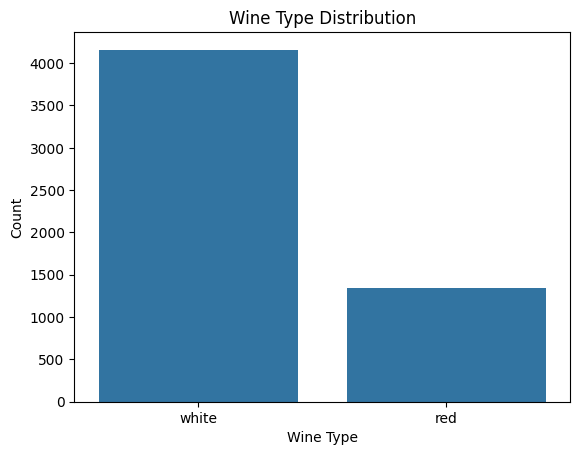

In [4]:
sns.countplot(data=train, x='type')

plt.title('Wine Type Distribution')
plt.xlabel('Wine Type')
plt.ylabel('Count')
plt.show()

화이트 와인이 레드 와인보다 약 3.1배 많다.

따라서 전체 데이터를 대상으로 성분 평균이나 분포를 확인하면 화이트 와인의 특성이 상대적으로 크게 반영될 수 있다.

이에 따라 이후 분석에서는 와인 종류별 성분 분포와 품질 분포를 개별적으로 비교하고, 종류별 분석 결과와 전체 분석 결과를 함께 확인한다.

###2. 와인 종류에 따른 화학적 성분 비교
레드 와인과 화이트 와인의 화학적 성분에 실제로 차이가 있는지 확인한다.

기존 데이터 분석에서 확인한 주요 변수의 평균은 다음과 같다.

In [5]:
features = [
    'fixed acidity',
    'volatile acidity',
    'citric acid',
    'residual sugar',
    'chlorides',
    'free sulfur dioxide',
    'total sulfur dioxide',
    'density',
    'pH',
    'sulphates',
    'alcohol'
]

type_mean = train.groupby('type')[features].mean().T

type_mean['차이(White-Red)'] = (
    type_mean['white'] - type_mean['red']
)

display(type_mean.round(3))

type,red,white,차이(White-Red)
fixed acidity,8.308,6.857,-1.451
volatile acidity,0.526,0.278,-0.248
citric acid,0.270,0.334,0.064
residual sugar,2.535,6.372,3.837
chlorides,0.088,0.046,-0.042
free sulfur dioxide,15.827,35.112,19.285
total sulfur dioxide,46.129,137.906,91.777
density,0.997,0.994,-0.003
pH,3.313,3.189,-0.123
sulphates,0.659,0.489,-0.169


주요 특징은 다음과 같다.
- 잔당(residual sugar): 화이트 와인이 레드 와인보다 약 2.5배 높다.
- 휘발성 산도(volatile acidity): 레드 와인이 화이트 와인보다 약 1.9배 높다.
- 알코올(alcohol): 두 종류의 평균 차이가 크지 않다.

즉, 와인 종류에 따라 화학적 성분의 차이가 나타나며 특히 잔당과 휘발성 산도에서 차이가 두드러진다.

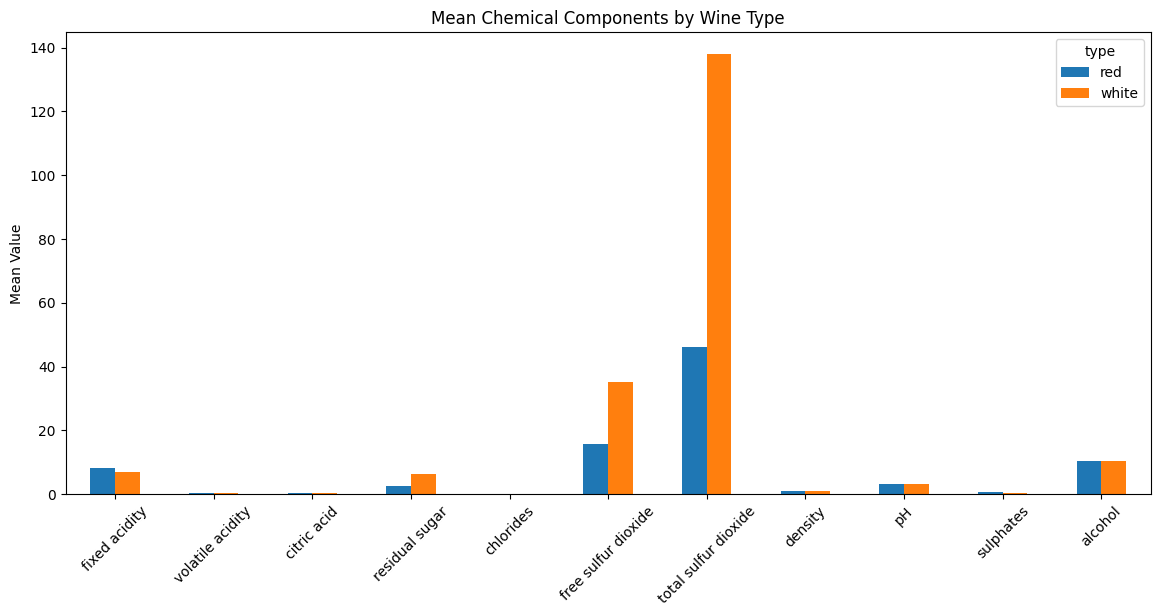

In [6]:
#종류별 성분 평균 비교
features = [
    'fixed acidity',
    'volatile acidity',
    'citric acid',
    'residual sugar',
    'chlorides',
    'free sulfur dioxide',
    'total sulfur dioxide',
    'density',
    'pH',
    'sulphates',
    'alcohol'
]

type_mean = train.groupby('type')[features].mean().T

type_mean.plot(
    kind='bar',
    figsize=(14, 6)
)

plt.title('Mean Chemical Components by Wine Type')
plt.ylabel('Mean Value')
plt.xticks(rotation=45)
plt.show()

단, 변수마다 측정 단위와 범위가 다르기 때문에 평균 비교 그래프를 한 번에 그리는 것만으로 차이를 판단하기는 어렵다.
-> 주요 성분별 boxplot 작성

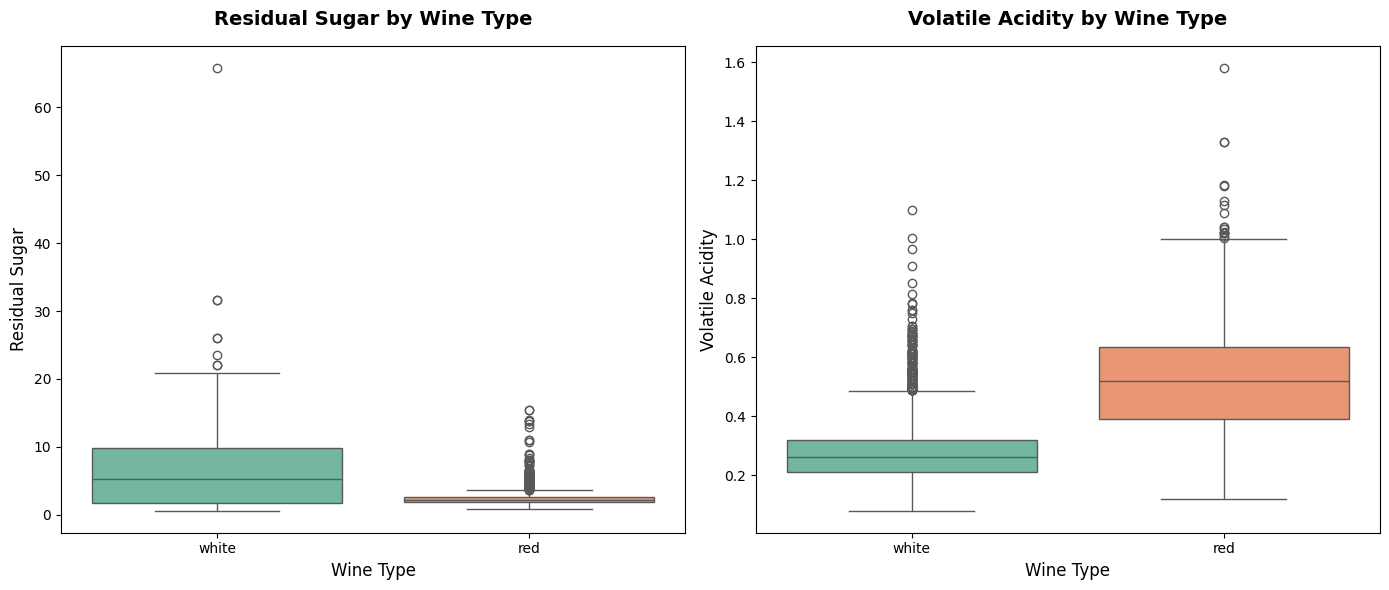

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(
    data=train,
    x='type',
    y='residual sugar',
    hue='type',
    palette='Set2',
    legend=False,
    ax=axes[0]
)

axes[0].set_title('Residual Sugar by Wine Type', fontsize=14, pad=15, fontweight='bold')
axes[0].set_xlabel('Wine Type', fontsize=12)
axes[0].set_ylabel('Residual Sugar', fontsize=12)

sns.boxplot(
    data=train,
    x='type',
    y='volatile acidity',
    hue='type',
    palette='Set2',
    legend=False,
    ax=axes[1]
)

axes[1].set_title('Volatile Acidity by Wine Type', fontsize=14, pad=15, fontweight='bold')
axes[1].set_xlabel('Wine Type', fontsize=12)
axes[1].set_ylabel('Volatile Acidity', fontsize=12)

plt.tight_layout()
plt.show()

분석을 통해 결정할 사항
- 와인 종류에 따라 성분의 분포가 얼마나 다른가?

  레드 와인과 화이트 와인은 화학적 성분의 평균에서 차이를 보인다.

- 특정 성분이 와인 종류를 구분하는 데 유용한가?

  특히 잔당은 화이트 와인에서 상대적으로 높고, 휘발성 산도는 레드 와인에서 상대적으로 높게 나타난다.

- type 변수를 모델의 입력 변수로 유지해야 하는가?

  종류에 따른 화학적 특성 차이가 존재하며, type 변수를 모델의 입력 변수로 유지할 필요가 있다.

다만 평균 차이만으로 두 종류의 분포가 완전히 구분된다고 판단할 수는 없으므로, 주요 성분의 분포와 이상치도 함께 확인한다.

###3. 와인 종류에 따른 품질 차이
성분 차이뿐 아니라 레드 와인과 화이트 와인의 실제 품질 평가에도 차이가 있는지 확인한다.

기존 분석 결과는 다음과 같다.

In [8]:
# 와인 종류별 평균 품질 계산
quality_by_type = train.groupby('type')['quality'].mean()

# 표 형태로 출력
quality_table = quality_by_type.reset_index()
quality_table.columns = ['구분', '평균 품질']

quality_table['평균 품질'] = quality_table['평균 품질'].round(3)

print(quality_table)

      구분  평균 품질
0    red  5.638
1  white  5.877


화이트 와인의 평균 품질이 레드 와인보다 약 0.239점 높다.

다만 평균만으로 두 종류의 품질 차이를 판단하기는 어렵다. 등급별 데이터 분포도 함께 확인해야 한다.

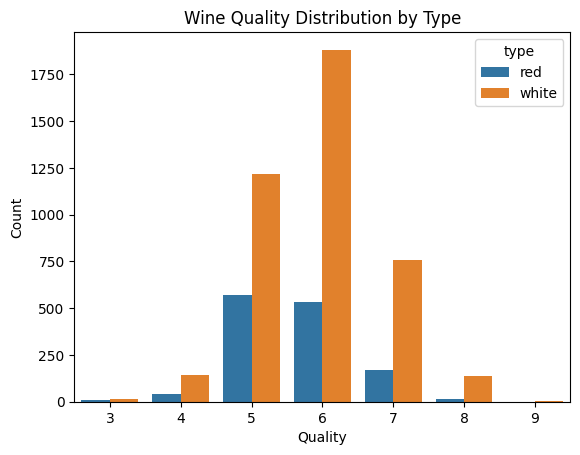

In [9]:
#와인 종류별 품질 등급 분포
sns.countplot(
    data=train,
    x='quality',
    hue='type'
)

plt.title('Wine Quality Distribution by Type')
plt.xlabel('Quality')
plt.ylabel('Count')
plt.show()

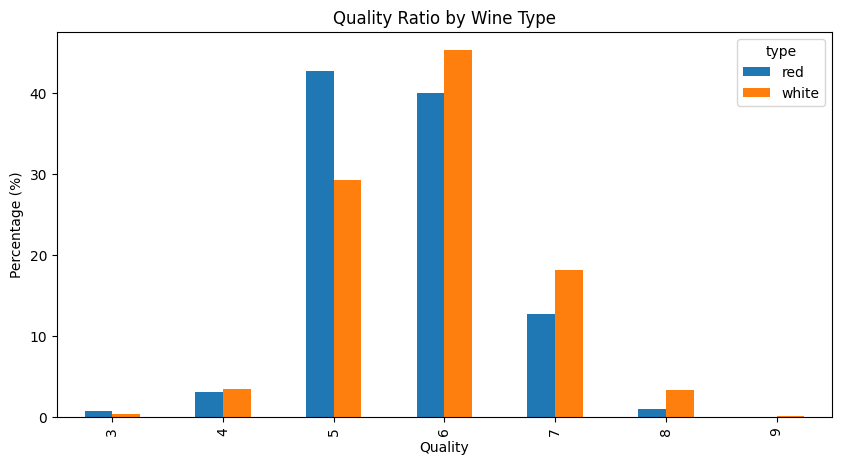

In [10]:
#와인 종류별 품질 등급 비율
quality_ratio = pd.crosstab(
    train['quality'],
    train['type'],
    normalize='columns'
) * 100

quality_ratio.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Quality Ratio by Wine Type')
plt.ylabel('Percentage (%)')
plt.xlabel('Quality')
plt.show()

두 번째 그래프는 특히 중요하다. 레드 와인과 화이트 와인의 데이터 개수 자체가 다르기 때문에 단순 개수보다 비율로 비교하는 것이 적절하다.

분석을 통해 확인할 사항
- 레드 와인과 화이트 와인 중 어느 쪽의 고품질 와인 비율이 높은가?

  기존 분석 결과에서는 화이트 와인의 평균 품질이 레드 와인보다 약 0.239점 높게 나타났다.

- 특정 품질 등급이 한 종류의 와인에 집중되어 있는가?

  레드 와인과 화이트 와인의 내부에서 해당 등급이 차지하는 비율을 보았을 때, 특정 품질 등급에 차이가 있었다.

- 평균 품질 차이가 실제 등급 분포에서도 나타나는가?

  화이트 와인의 평균 품질이 더 높은 것은 상대적으로 높은 품질 등급의 비율이 더 높은 분포와 일치했다. 다만, 두 와인 모두 5~6점 등급에 데이터가 많이 분포하므로, 화이트 와인의 품질이 전반적으로 매우 높다고 해석해서는 안된다.

###4. 와인 종류별 품질과 성분의 관계
앞선 팀원의 상관관계 분석과 연결되는 부분이다.

전체 데이터를 한꺼번에 분석하면 레드 와인과 화이트 와인의 서로 다른 특성이 섞일 수 있다.

따라서 와인 종류별로 품질과 화학 성분 사이의 상관관계를 비교한다.

기존 상관관계 EDA에서 확인한 결과는 다음과 같다.

In [11]:
# 분석할 변수 지정
features = [
    'alcohol',
    'volatile acidity',
    'citric acid',
    'fixed acidity',
    'sulphates',
    'pH'
]

# 전체 와인의 상관계수
total_corr = train[features + ['quality']].corr()['quality'][features]

# Red 와인의 상관계수
red_corr = train[train['type'] == 'red'][features + ['quality']].corr()['quality'][features]

# White 와인의 상관계수
white_corr = train[train['type'] == 'white'][features + ['quality']].corr()['quality'][features]

# 하나의 표로 합치기
corr_table = pd.DataFrame({
    '전체': total_corr,
    'Red': red_corr,
    'White': white_corr
})

# 소수점 셋째 자리까지 표시
corr_table = corr_table.round(3)

# 표 출력
print(corr_table)

                     전체    Red  White
alcohol           0.440  0.476  0.430
volatile acidity -0.262 -0.384 -0.192
citric acid       0.079  0.201 -0.005
fixed acidity    -0.077  0.116 -0.107
sulphates         0.042  0.258  0.056
pH                0.018 -0.041  0.091


여기서 주목할 부분은 일부 변수에서 상관관계의 방향이 달라진다는 점이다.
- citric acid: Red에서는 양의 상관, White에서는 거의 상관이 없다.
- fixed acidity: Red에서는 양의 상관, White에서는 음의 상관을 보인다.
- pH: Red에서는 음의 상관, White에서는 양의 상관을 보인다.
- alcohol: 두 종류 모두 양의 상관관계가 나타난다.

즉, 와인 종류에 따라 품질과 성분 사이의 관계가 달라질 가능성이 있다.

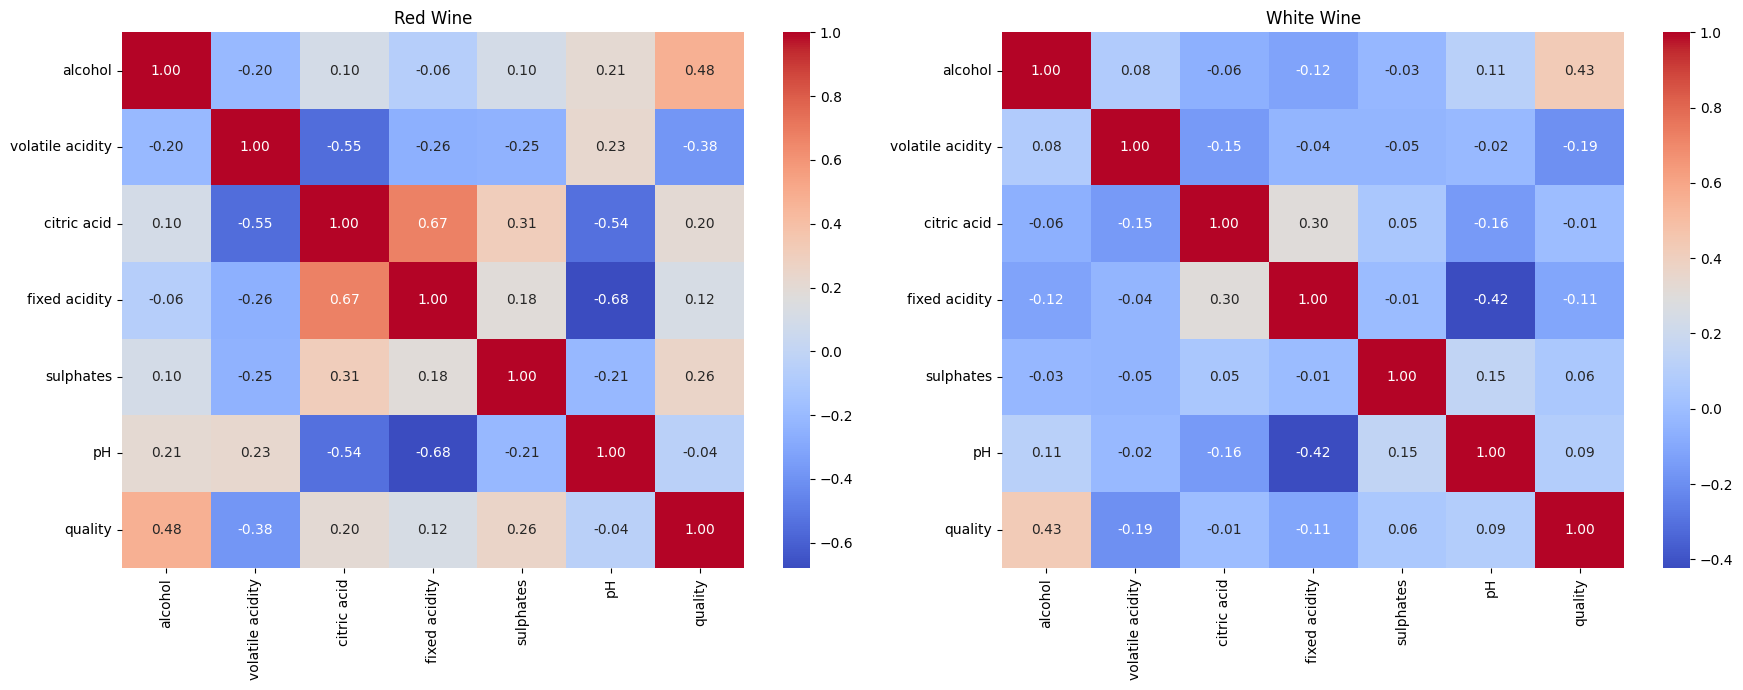

In [12]:
#종류별 상관관계 히트맵
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, wine_type in zip(axes, ['red', 'white']):
    subset = train[train['type'] == wine_type]

    corr = subset[features + ['quality']].corr()

    sns.heatmap(
        corr,
        annot=True,
        cmap='coolwarm',
        fmt='.2f',
        ax=ax
    )

    ax.set_title(f'{wine_type.capitalize()} Wine')

plt.tight_layout()
plt.show()

분석을 통해 결정할 사항
- 와인 종류에 따라 품질에 영향을 미치는 주요 성분이 달라지는가?

  일부 성분의 품질과의 상관관계 방향이 와인 종류에 따라 달라지는 것으로 나타났다. 특히 fixed acidity와 pH는 레드 와인과 화이트 와인에서 서로 다른 방향의 상관관계를 보였다.

- 전체 데이터에서 나타난 상관관계가 종류별로도 유지되는가?

  와인 종류에 따라 품질에 영향을 미치는 주요 성분이 달라짐으로 전체 데이터를 대상으로 계산한 상관계수만으로는 와인 종류별 특성을 충분히 설명하기 어려울 수 있다.

- type을 모델에 포함하는 것이 필요한가?

  레드 와인과 화이트 와인은 화학적 성분과 품질 등급 분포에 차이가 있으므로, type을 모델의 입력 변수로 포함할 수 있다.
  
하지만, 레드 와인과 화이트 와인을 통합하여 학습한 모델의 경우 분리하여 학습한 모델의 정확도와 0.0035로 매우 작은 차이를 보인다. 따라서, 분리 모델이 확실히 우수하다고 보기 어렵고, 분리 모델은 성능 비교용으로 유지하는게 적절하다.

###5. 품질 등급의 클래스 불균형 분석
이번에는 와인 종류가 아닌 품질 등급(quality)에 초점을 맞춘다.

현재 품질 등급별 데이터 개수는 다음과 같다.

In [13]:
# 품질 등급별 데이터 개수 계산
quality_count = train['quality'].value_counts().sort_index()

# 품질 등급별 비율 계산
quality_ratio = train['quality'].value_counts(normalize=True).sort_index() * 100

# 표로 정리
quality_table = pd.DataFrame({
    '개수': quality_count,
    '비율': quality_ratio
})

# 비율은 소수점 둘째 자리까지 표시
quality_table['비율'] = quality_table['비율'].map(lambda x: f'{x:.2f}%')

# 품질 등급을 인덱스에서 열로 변경
quality_table.index.name = '품질 등급'
quality_table = quality_table.reset_index()

# 표 출력
print(quality_table)

   품질 등급    개수      비율
0      3    26   0.47%
1      4   186   3.38%
2      5  1788  32.53%
3      6  2416  43.95%
4      7   924  16.81%
5      8   152   2.77%
6      9     5   0.09%


####5-1. 불균형 처리 방법 비교
이번에는 불균형 처리를 하지 않은 모델과 처리한 모델의 성능을 직접 비교한다.

각	방법	특징

1.	원본 데이터	- 별도 불균형 처리 없이 학습
2.	Class Weight -	소수 등급에 더 높은 가중치 부여
3.	SMOTE -	소수 등급의 가상 데이터 생성
4.	Random Oversampling -	기존 소수 등급 데이터 복제

####5-2. 불균형 처리 전후 모델 성능 비교
이 부분은 실제 실험을 진행해야 결론을 내릴 수 있다.

우선 Random Forest를 기준 모델로 고정하고 비교한다.
- 모델: RandomForestClassifier
- 데이터 분할: StratifiedKFold
- 교차검증: 5-Fold
- 평가 지표: Accuracy
- 추가 확인: Macro F1-score



In [14]:
models = {
    '미적용': RandomForestClassifier(n_estimators=100, random_state=42),

    'Class Weight': RandomForestClassifier(
        n_estimators=100, class_weight='balanced', random_state=42
    ),

    'SMOTE': Pipeline([
        ('smote', SMOTE(k_neighbors=2, random_state=42)),
        ('model', RandomForestClassifier(n_estimators=100, random_state=42))
    ]),

    'Random Oversampling': Pipeline([
        ('over', RandomOverSampler(random_state=42)),
        ('model', RandomForestClassifier(n_estimators=100, random_state=42))
    ])
}

results = []

for name, model in models.items():
    scores = cross_validate(
        model, X, y, cv=5,
        scoring=['accuracy', 'f1_macro']
    )

    results.append([
        name,
        scores['test_accuracy'].mean(),
        scores['test_f1_macro'].mean()
    ])

result_df = pd.DataFrame(
    results,
    columns=['불균형 처리', 'Accuracy', 'Macro F1']
)

print(result_df.round(4))

                불균형 처리  Accuracy  Macro F1
0                  미적용    0.6740    0.3748
1         Class Weight    0.6725    0.3755
2                SMOTE    0.6447    0.3979
3  Random Oversampling    0.6720    0.3924


SMOTE와 Random Oversampling은 교차검증 과정에서 데이터 누출이 발생하지 않도록 각 Fold의 학습 데이터에만 적용해야 한다. imblearn.pipeline.Pipeline을 사용하면 된다.

또한 9점 데이터가 5개뿐이므로 SMOTE의 기본 k_neighbors=5는 그대로 사용하기 어렵다. Fold별 학습 데이터 수를 확인하고 이보다 작은 이웃 수를 설정해야 한다.

####5-3. 불균형 처리가 실제로 필요한가?
이번 프로젝트의 최종 평가 지표는 Accuracy(정확도) 이다.

따라서 불균형 처리가 반드시 좋은 결과를 가져오는 것은 아니다.

예를 들어 소수 등급인 3점과 9점을 더 잘 맞히도록 학습하면, 상대적으로 데이터가 많은 5·6·7점의 예측 정확도가 낮아질 수 있다.

기존 회의 자료에서도 다음과 같은 결과를 확인했다.
- Random Forest가 3·4·8·9점 데이터 73개 중 16개를 맞혔다.
- 전체 데이터에서 6점만 예측하는 경우 정확도는 0.4395였다.
- 기존 분석에서는 불균형 처리를 하지 않는 방향을 우선 제안했다.

예상되는 결론 및 전처리 방향
1. 원본 데이터를 유지한 모델을 기본 모델로 설정한다.
2. Class Weight와 SMOTE를 적용한 모델을 추가로 실험한다.
3. 정확도가 상승하는지 비교한다.
4. 정확도가 하락한다면 불균형 처리를 적용하지 않는다.

단, 정확도만 비교하면 소수 등급의 예측 성능을 놓칠 수 있으므로 Macro F1과 등급별 Recall도 함께 확인하는 것이 좋다.

###6. EDA 종합 정리 및 전처리 제안
지금까지 분석한 내용을 바탕으로 다음과 같은 방향을 제안한다.

1. 와인 종류별 특성
- 화이트 와인은 레드 와인보다 잔당이 약 2.5배 많다.
- 레드 와인은 화이트 와인보다 휘발성 산도가 약 1.9배 높다.
- 평균 품질은 화이트 와인이 약 0.239점 높다.
- 일부 화학 성분은 와인 종류에 따라 품질과의 상관관계 방향이 달라진다.

-> 따라서 와인 종류에 따른 특성 차이를 모델에 반영한다.

2. 모델링 방향
- type 변수는 반드시 유지한다.
- 레드와 화이트를 분리한 모델과 통합 모델을 비교하되, 현재까지는 통합 모델을 우선한다.
- 와인 종류별 성분 차이를 고려해 파생변수 생성도 검토한다.

3. 클래스 불균형
- 5·6·7점이 전체의 약 93.3%를 차지한다.
- 3점과 9점의 데이터가 매우 적다.
- 정확도 평가이므로 불균형 처리를 무조건 적용하지 않는다.
- 원본 데이터를 기본 학습 데이터로 사용한다.
- Class Weight와 SMOTE를 적용한 모델은 비교 실험으로 유지하며, 기존 비교 결과에서 원본 데이터 모델보다 성능이 향상되지 않았다면 불균형 처리를 적용하지 않는다.
- 최종 모델의 평가는 Accuracy를 기준으로 하며, Macro F1과 등급별 Recall을 함께 확인한다.

-> Random Oversampling은 Macro F1이 0.3924로 두번째로 높고, Accuracy는 0.6720으로 원본 데이터의 Accuracy와 거의 같다. 따라서, 소수 클래스 예측 성능을 함께 고려해 Random Oversampling을 최종 불균형 처리 방식으로 선택하는 게 합리적이다.